In [1]:
import glob as gb
import json
import re
import numpy as np
import cv2

import matplotlib.pyplot as plt
from tqdm import tqdm

In [ ]:
# FOV in horizontal and vertical axes (replace with the HMD values)
fov_horizontal, fov_vertical = 108.77, 111.53


def convert_hor_degre(degrees):
    return (degrees + 180 + 360) % 360


def convert_ver_degree(degrees):
    # -1 because the y-axis is inverted for opencv
    return ((-1) * degrees + 90 + 360) % 360


def atoi(text):
    return int(text) if text.isdigit() else text


def natural_keys(text):
    return [atoi(c) for c in re.split(r"(\d+)", text)]


def visualize_frame(
    heatmap,
    frame,
    fov_top,
    fov_botom,
    fov_left,
    fov_right,
    width,
    height,
    giw_long,
    giw_lat,
):
    cropped_frame = np.zeros((heatmap.shape[0], heatmap.shape[1], 3), dtype=np.uint8)
    visualization_frame = frame.copy()
    # Handle vertical wrapping
    if fov_top < 0:
        top_padding = np.zeros((-fov_top, cropped_frame.shape[1], 3), dtype=np.uint8)
        cropped_frame = np.vstack((top_padding, cropped_frame))
        heatmap = heatmap[-fov_top:, :]
    if fov_botom > height:
        bottom_padding = np.zeros(
            (fov_botom - height, cropped_frame.shape[1], 3), dtype=np.uint8
        )
        cropped_frame = np.vstack((cropped_frame, bottom_padding))
        heatmap = heatmap[: fov_botom - height, :]
    # considering wrapping for horizontal
    if fov_right > width:
        cropped_frame_left = frame[fov_top:fov_botom, fov_left:].copy()
        cropped_frame_right = frame[fov_top:fov_botom, : fov_right - width].copy()
        cropped_frame = np.hstack((cropped_frame_left, cropped_frame_right))
        # print(heatmap.shape, cropped_frame_left.shape,cropped_frame_right.shape)
        visualization_frame[fov_top:fov_botom, fov_left:] = cv2.addWeighted(
            frame[fov_top:fov_botom, fov_left:],
            0.8,
            heatmap[:, : cropped_frame_left.shape[1]],
            0.2,
            0,
        )
        visualization_frame[fov_top:fov_botom, : fov_right - width] = cv2.addWeighted(
            frame[fov_top:fov_botom, : fov_right - width],
            0.8,
            heatmap[:, cropped_frame_left.shape[1] :],
            0.2,
            0,
        )
        cv2.rectangle(
            visualization_frame,
            (fov_left, fov_top),
            (width, fov_botom),
            (255, 255, 0),
            4,
        )
        cv2.rectangle(
            visualization_frame,
            (0, fov_top),
            (fov_right - width, fov_botom),
            (255, 255, 0),
            4,
        )
    elif fov_left < 0:
        cropped_frame_left = frame[fov_top:fov_botom, fov_left:].copy()
        cropped_frame_right = frame[fov_top:fov_botom, :fov_right].copy()
        cropped_frame = np.hstack((cropped_frame_left, cropped_frame_right))
        visualization_frame[fov_top:fov_botom, fov_left:] = cv2.addWeighted(
            frame[fov_top:fov_botom, fov_left:],
            0.8,
            heatmap[:, : cropped_frame_left.shape[1]],
            0.2,
            0,
        )
        visualization_frame[fov_top:fov_botom, :fov_right] = cv2.addWeighted(
            frame[fov_top:fov_botom, :fov_right],
            0.8,
            heatmap[:, cropped_frame_left.shape[1] :],
            0.2,
            0,
        )
        cv2.rectangle(
            visualization_frame,
            (width + fov_left, fov_top),
            (width, fov_botom),
            (255, 255, 0),
            4,
        )
        cv2.rectangle(
            visualization_frame,
            (0, fov_top),
            (fov_right, fov_botom),
            (255, 255, 0),
            4,
        )
    else:
        try:
            cropped_frame = frame[fov_top:fov_botom, fov_left:fov_right].copy()
            visualization_frame[fov_top:fov_botom, fov_left:fov_right] = (
                cv2.addWeighted(
                    frame[fov_top:fov_botom, fov_left:fov_right],
                    0.8,
                    heatmap,
                    0.2,
                    0,
                )
            )
            cv2.rectangle(
                visualization_frame,
                (fov_left, fov_top),
                (fov_right, fov_botom),
                (255, 255, 0),
                4,
            )
        except:
            pass

    # Handle wrapping for circle (giw_long, giw_lat)
    center = (
        int(convert_hor_degre(giw_long) * width / 360),
        int(convert_ver_degree(giw_lat) * height / 180),
    )
    if center[0] < 0:
        cv2.circle(
            visualization_frame,
            (width + center[0], center[1]),
            120,
            (0, 255, 0),
            4,
        )
    else:
        cv2.circle(visualization_frame, center, 120, (0, 255, 0), 4)

    return visualization_frame

In [ ]:
sal_res_path = "/home/alien/Documents/access/processed_dataset/eht_dataset_salvideos/Video_8/User_8_Task_1"

video_path = (
    "/home/alien/Documents/access/eht_dataset/Videos/Video 8 - LOSC Football.mp4"
)
json_paths = gb.glob(sal_res_path + "/*.json")
json_paths.sort(key=natural_keys)

# Create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec
output_video = cv2.VideoWriter(
    "/home/alien/Documents/access/results/fov_sal_vid8_usr8_task1_gazetrack.mp4",
    fourcc,
    30.0,
    (1280, 720),
)
# Open video
vcap = cv2.VideoCapture(video_path)
sal_fn = 0
prev_center = None
for json_path in tqdm(json_paths):
    sal_video_path = json_path.replace(".json", ".mp4")
    # Open sal video
    scap = cv2.VideoCapture(sal_video_path)
    # Open json metadata
    with open(json_path) as json_file:
        data = json.load(json_file)
    for frame_data in data:
        fn = frame_data["frame_number"]
        fov_top = frame_data["fov_top"]
        fov_botom = frame_data["fov_bottom"]
        fov_left = frame_data["fov_left"]
        fov_right = frame_data["fov_right"]
        giw_long = frame_data["giw_long"]
        giw_lat = frame_data["giw_lat"]
        sal_fn += 1
        # print('Frame number:',fn)
        # Set the frame number and get frame
        vcap.set(cv2.CAP_PROP_POS_FRAMES, fn - 1)
        vres, frame = vcap.read()
        if vres:
            # Video dimensions
            width, height = frame.shape[1], frame.shape[0]
            # Set the sal frame number and get frame
            scap.set(cv2.CAP_PROP_POS_FRAMES, sal_fn - 1)
            sres, sal_frame = scap.read()
            if sres:
                sal_frame = cv2.cvtColor(sal_frame, cv2.COLOR_BGR2GRAY)
                # Saliency result preprocess
                normalized_grayscale = sal_frame / 255.0
                heatmap = cv2.applyColorMap(
                    np.uint8(normalized_grayscale * 255), cv2.COLORMAP_JET
                )
                heatmap = cv2.resize(
                    heatmap, (abs(fov_left - fov_right), abs(fov_top - fov_botom))
                )
                visualization_frame = visualize_frame(
                    heatmap,
                    frame,
                    fov_top,
                    fov_botom,
                    fov_left,
                    fov_right,
                    width,
                    height,
                    giw_long,
                    giw_lat,
                )
                # Calculate center coordinates for the current frame
                giw_center = (
                    int(convert_hor_degre(giw_long) * width / 360),
                    int(convert_ver_degree(giw_lat) * height / 180),
                )
                # Track circle movement with horizontal wrapping consideration
                if prev_center is not None:
                    # Handle horizontal wrapping (assuming 360-degree video)
                    if prev_center[0] < 0 and giw_center[0] > width:
                        prev_center_adjusted = (width + prev_center[0], prev_center[1])
                    elif prev_center[0] > width and giw_center[0] < 0:
                        prev_center_adjusted = (0, prev_center[1])
                    else:
                        prev_center_adjusted = prev_center
                    # Draw a line connecting the previous and current center
                    cv2.line(
                        visualization_frame,
                        prev_center_adjusted,
                        giw_center,
                        (
                            0,
                            255,
                        ),
                        4,
                    )  # Red line
                # Update previous center for the next iteration
                prev_center = giw_center
                visualization_frame = cv2.resize(visualization_frame, (1280, 720))

                # Save the current frame to the video file
                output_video.write(visualization_frame)
                # Display the visualization frame
                # plt.figure(figsize=(15, 9))
                # plt.imshow(cv2.cvtColor(visualization_frame, cv2.COLOR_BGR2RGB))
                # plt.axis("off")  # Turn off axis labels
                # plt.tight_layout()
    sal_fn = 0
    scap.release()
vcap.release()
output_video.release()

  0%|          | 0/30 [00:00<?, ?it/s]/tmp/ipykernel_2289564/2464150158.py:200: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(15, 9))
  0%|          | 0/30 [00:10<?, ?it/s]


KeyboardInterrupt: 

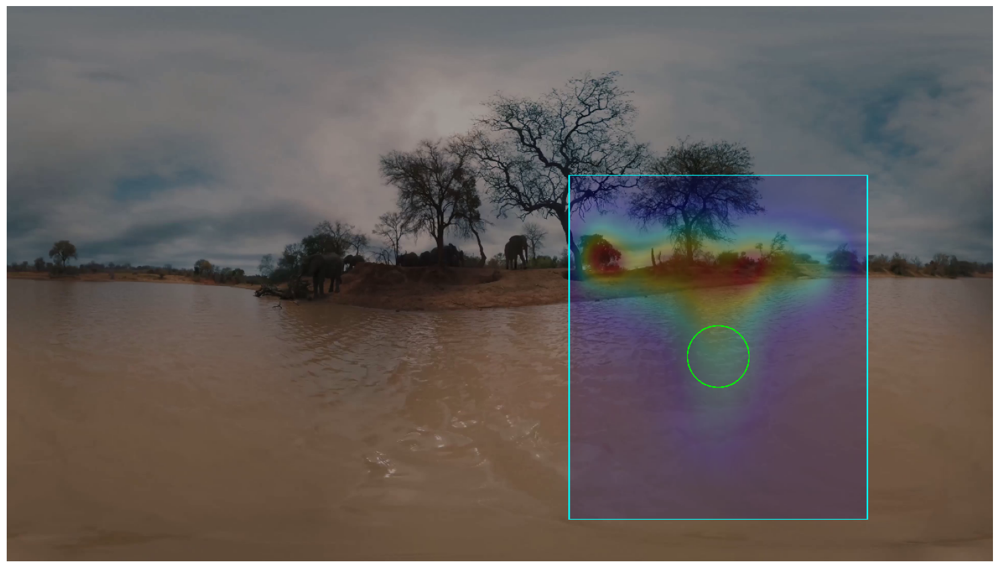

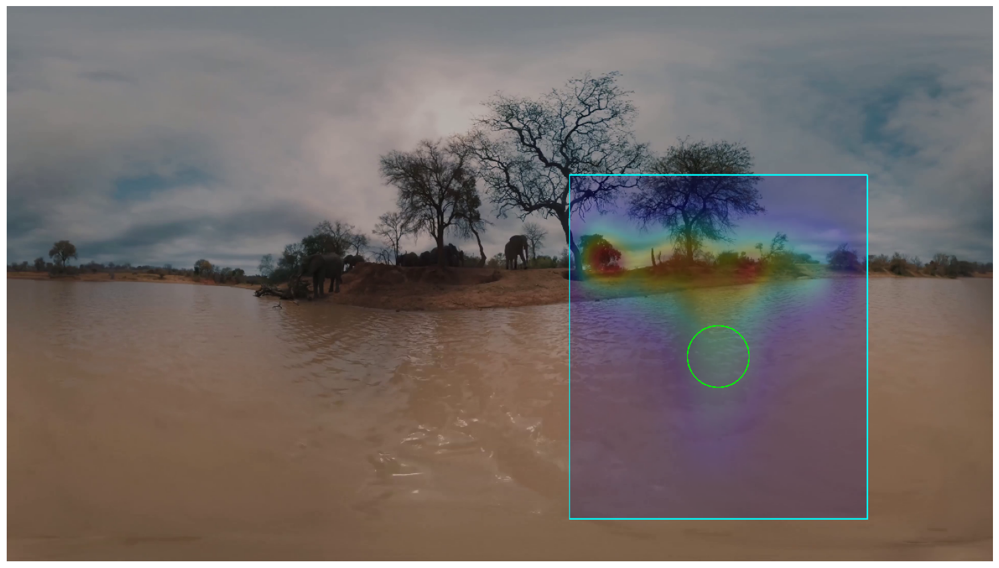

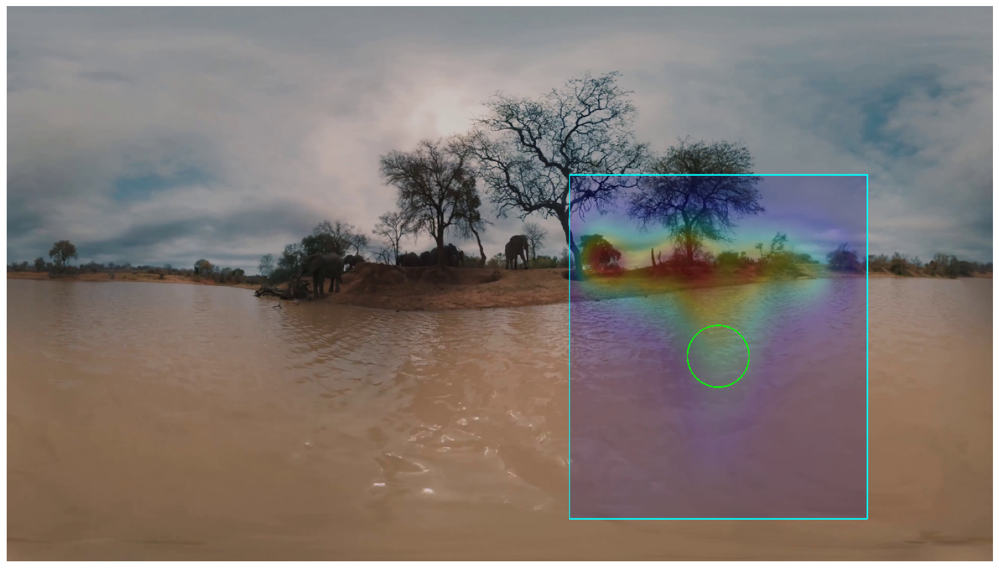

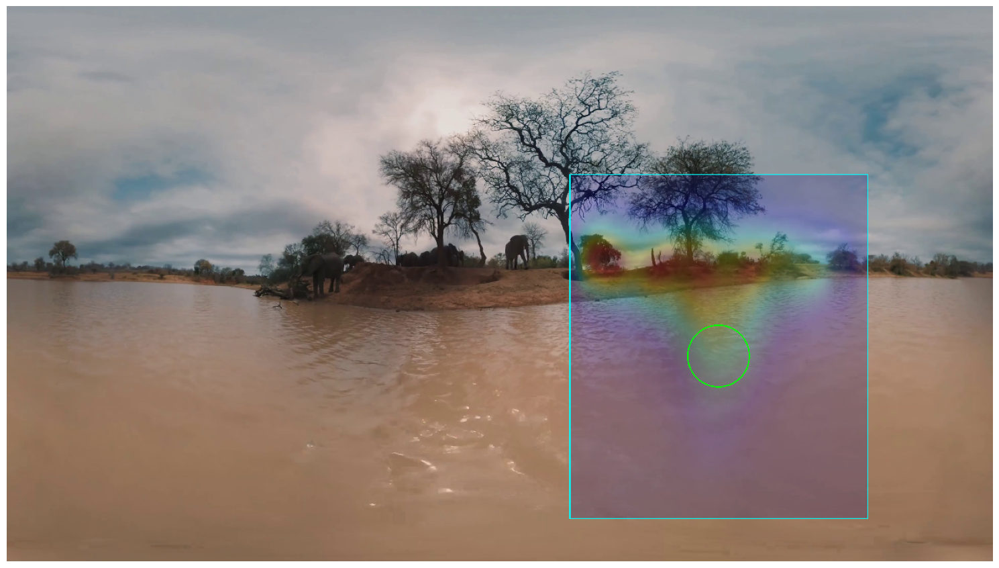

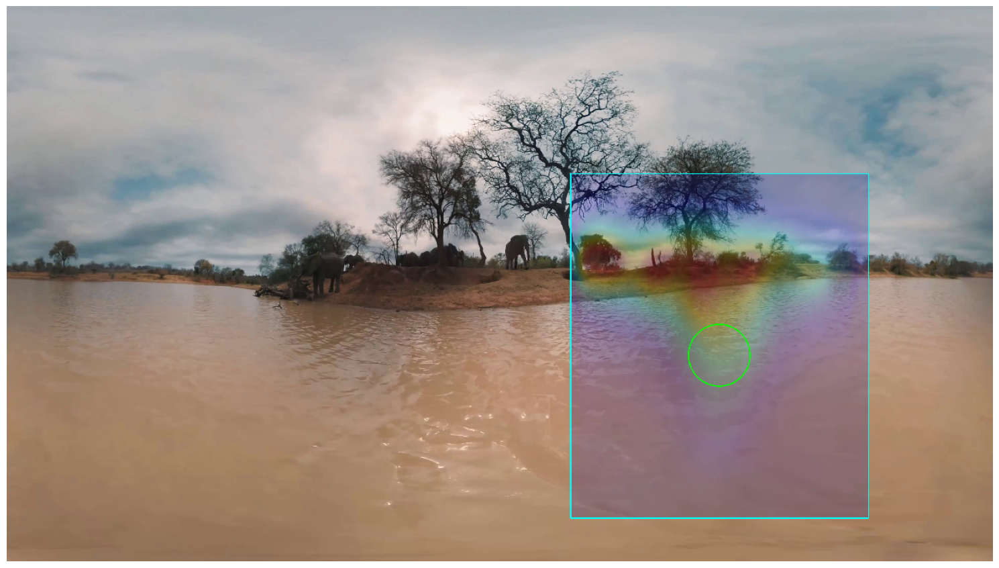

...

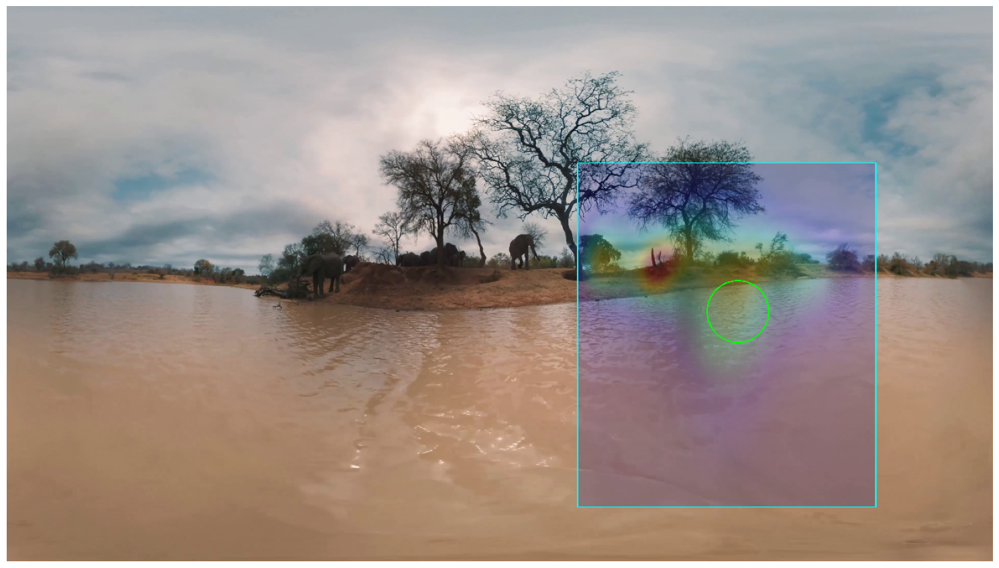

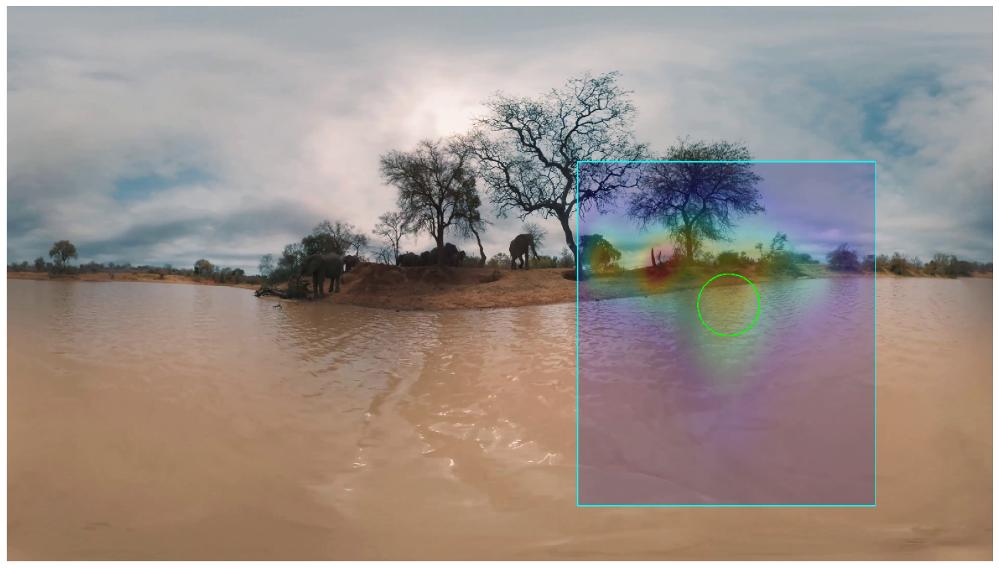

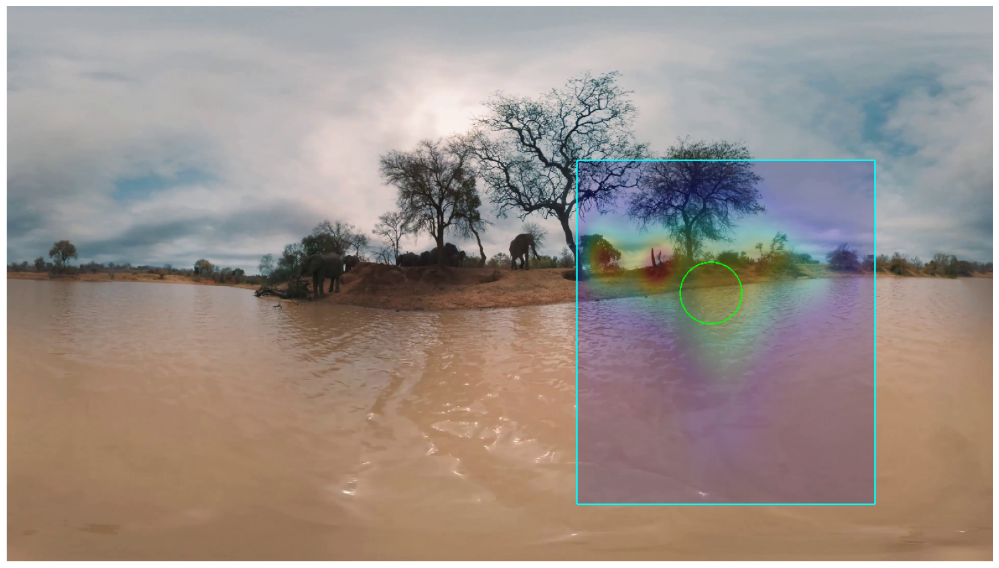

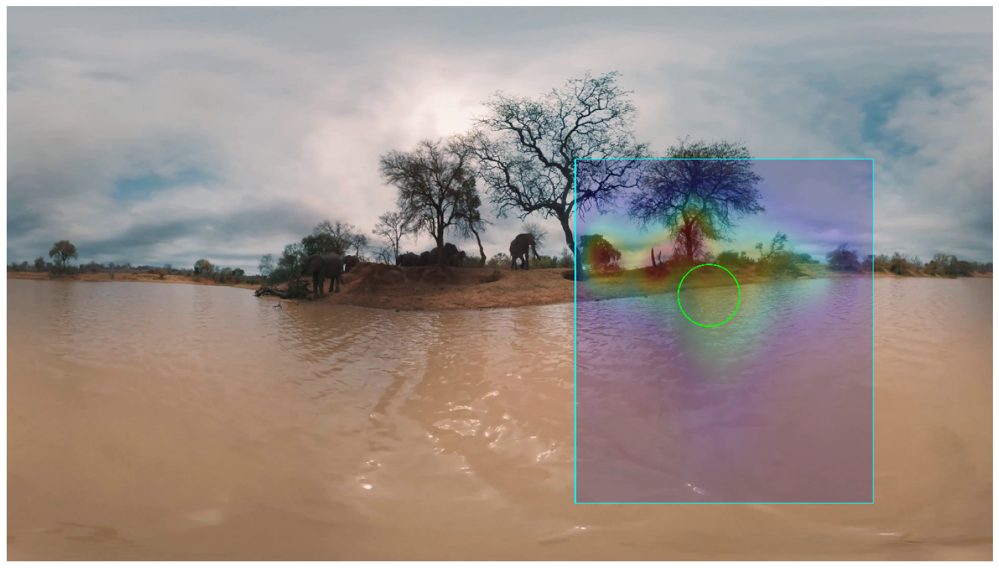

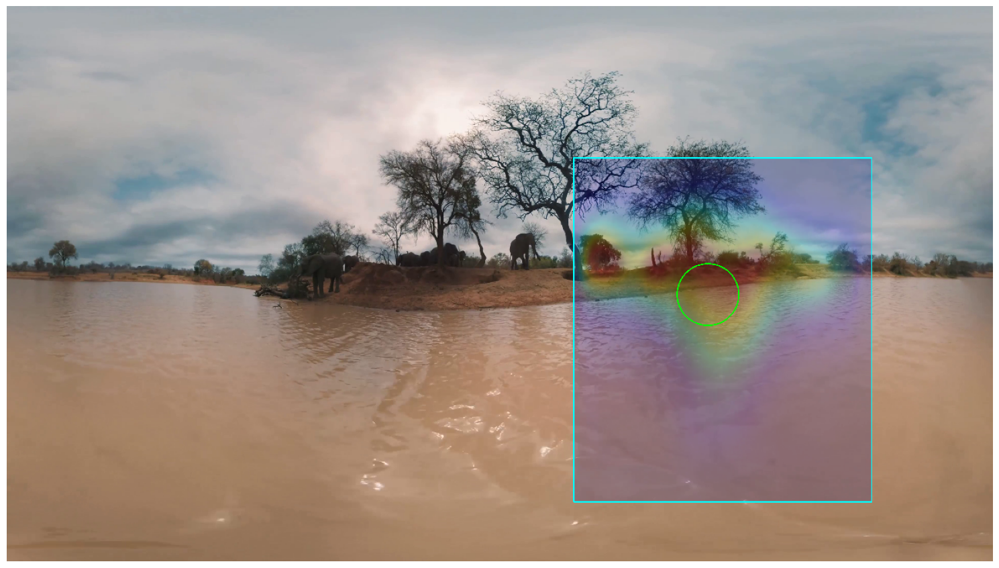

In [5]:
# FOV in horizontal and vertical axes (replace with the HMD values)
fov_horizontal, fov_vertical = 108.77, 111.53


def convert_hor_degre(degrees):
    return (degrees + 180 + 360) % 360


def convert_ver_degree(degrees):
    # -1 because the y-axis is inverted for opencv
    return ((-1) * degrees + 90 + 360) % 360


def atoi(text):
    return int(text) if text.isdigit() else text


def natural_keys(text):
    return [atoi(c) for c in re.split(r"(\d+)", text)]


sal_res_path = "/home/alien/Documents/access/processed_dataset/eht_dataset_salvideos/Video_4/User_2_Task_1"

video_path = "/home/alien/Documents/access/eht_dataset/Videos/Video 4 - Elephants.mp4"
json_paths = gb.glob(sal_res_path + "/*.json")
json_paths.sort(key=natural_keys)

# Create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec
output_video = cv2.VideoWriter(
    "/home/alien/Documents/access/results/fov_sal_vid4_usr2_task1.mp4",
    fourcc,
    30.0,
    (1280, 720),
)
# Open video
vcap = cv2.VideoCapture(video_path)
sal_fn = 0
for json_path in tqdm(json_paths):
    sal_video_path = json_path.replace(".json", ".mp4")
    # Open sal video
    scap = cv2.VideoCapture(sal_video_path)
    # Open json metadata
    with open(json_path) as json_file:
        data = json.load(json_file)
    for frame_data in data:
        fn = frame_data["frame_number"]
        fov_top = frame_data["fov_top"]
        fov_botom = frame_data["fov_bottom"]
        fov_left = frame_data["fov_left"]
        fov_right = frame_data["fov_right"]
        sal_fn += 1
        # print('Frame number:',fn)
        # Set the frame number and get frame
        vcap.set(cv2.CAP_PROP_POS_FRAMES, fn - 1)
        vres, frame = vcap.read()
        if vres:
            # Video dimensions
            width, height = frame.shape[1], frame.shape[0]
            # Create a copy of the frame to draw the rectangle on
            visualization_frame = frame.copy()
            # Set the sal frame number and get frame
            scap.set(cv2.CAP_PROP_POS_FRAMES, sal_fn - 1)
            sres, sal_frame = scap.read()
            if sres:
                sal_frame = cv2.cvtColor(sal_frame, cv2.COLOR_BGR2GRAY)
                # Saliency result preprocess
                normalized_grayscale = sal_frame / 255.0
                heatmap = cv2.applyColorMap(
                    np.uint8(normalized_grayscale * 255), cv2.COLORMAP_JET
                )
                heatmap = cv2.resize(
                    heatmap, (abs(fov_left - fov_right), abs(fov_top - fov_botom))
                )

                # Handle vertical wrapping
                if fov_top < 0:
                    top_padding = np.zeros(
                        (-fov_top, cropped_frame.shape[1], 3), dtype=np.uint8
                    )
                    cropped_frame = np.vstack((top_padding, cropped_frame))
                    heatmap = heatmap[-fov_top:, :]
                if fov_botom > height:
                    bottom_padding = np.zeros(
                        (fov_botom - height, cropped_frame.shape[1], 3), dtype=np.uint8
                    )
                    cropped_frame = np.vstack((cropped_frame, bottom_padding))
                    heatmap = heatmap[: fov_botom - height, :]
                # considering wrapping for horizontal
                if fov_right > width:
                    cropped_frame_left = frame[fov_top:fov_botom, fov_left:].copy()
                    cropped_frame_right = frame[
                        fov_top:fov_botom, : fov_right - width
                    ].copy()
                    cropped_frame = np.hstack((cropped_frame_left, cropped_frame_right))
                    # print(heatmap.shape, cropped_frame_left.shape,cropped_frame_right.shape)
                    visualization_frame[fov_top:fov_botom, fov_left:] = cv2.addWeighted(
                        frame[fov_top:fov_botom, fov_left:],
                        0.8,
                        heatmap[:, : cropped_frame_left.shape[1]],
                        0.2,
                        0,
                    )
                    visualization_frame[fov_top:fov_botom, : fov_right - width] = (
                        cv2.addWeighted(
                            frame[fov_top:fov_botom, : fov_right - width],
                            0.8,
                            heatmap[:, cropped_frame_left.shape[1] :],
                            0.2,
                            0,
                        )
                    )
                    cv2.rectangle(
                        visualization_frame,
                        (fov_left, fov_top),
                        (width, fov_botom),
                        (255, 255, 0),
                        4,
                    )
                    cv2.rectangle(
                        visualization_frame,
                        (0, fov_top),
                        (fov_right - width, fov_botom),
                        (255, 255, 0),
                        4,
                    )
                elif fov_left < 0:
                    cropped_frame_left = frame[fov_top:fov_botom, fov_left:].copy()
                    cropped_frame_right = frame[fov_top:fov_botom, :fov_right].copy()
                    cropped_frame = np.hstack((cropped_frame_left, cropped_frame_right))
                    visualization_frame[fov_top:fov_botom, fov_left:] = cv2.addWeighted(
                        frame[fov_top:fov_botom, fov_left:],
                        0.8,
                        heatmap[:, : cropped_frame_left.shape[1]],
                        0.2,
                        0,
                    )
                    visualization_frame[fov_top:fov_botom, :fov_right] = (
                        cv2.addWeighted(
                            frame[fov_top:fov_botom, :fov_right],
                            0.8,
                            heatmap[:, cropped_frame_left.shape[1] :],
                            0.2,
                            0,
                        )
                    )
                    cv2.rectangle(
                        visualization_frame,
                        (width + fov_left, fov_top),
                        (width, fov_botom),
                        (255, 255, 0),
                        4,
                    )
                    cv2.rectangle(
                        visualization_frame,
                        (0, fov_top),
                        (fov_right, fov_botom),
                        (255, 255, 0),
                        4,
                    )
                else:
                    cropped_frame = frame[fov_top:fov_botom, fov_left:fov_right].copy()
                    visualization_frame[fov_top:fov_botom, fov_left:fov_right] = (
                        cv2.addWeighted(
                            frame[fov_top:fov_botom, fov_left:fov_right],
                            0.8,
                            heatmap,
                            0.2,
                            0,
                        )
                    )
                    cv2.rectangle(
                        visualization_frame,
                        (fov_left, fov_top),
                        (fov_right, fov_botom),
                        (255, 255, 0),
                        4,
                    )

                # Handle wrapping for circle (giw_long, giw_lat)
                center = (
                    int(convert_hor_degre(frame_data["giw_long"]) * width / 360),
                    int(convert_ver_degree(frame_data["giw_lat"]) * height / 180),
                )
                if center[0] < 0:
                    cv2.circle(
                        visualization_frame,
                        (width + center[0], center[1]),
                        120,
                        (0, 255, 0),
                        4,
                    )
                else:
                    cv2.circle(visualization_frame, center, 120, (0, 255, 0), 4)

                visualization_frame = cv2.resize(visualization_frame, (1280, 720))
                # Save the current frame to the video file
                # output_video.write(visualization_frame)
                # Display the visualization frame
                plt.figure(figsize=(15, 9))
                plt.imshow(cv2.cvtColor(visualization_frame, cv2.COLOR_BGR2RGB))
                plt.axis("off")  # Turn off axis labels
                plt.tight_layout()
    sal_fn = 0
    scap.release()
vcap.release()
output_video.release()

In [22]:
visualization_frame[fov_top:fov_botom, fov_left:] = cv2.addWeighted(
    frame[fov_top:fov_botom, fov_left:],
    0.8,
    heatmap[:, : cropped_frame_left.shape[1]],
    0.2,
    0,
)

In [17]:
heatmap[:, : cropped_frame_left.shape[1]].shape

(1339, 567, 3)

In [15]:
fov_top - fov_botom, fov_left

(-1339, -567)

In [34]:
visualization_frame.shape

(2160, 3840, 3)

In [35]:
frame_data["fov_left"], frame_data["fov_right"]

(-566, 594)

In [32]:
visualization_frame[
    frame_data["fov_top"] : frame_data["fov_bottom"],
    frame_data["fov_left"] : frame_data["fov_right"],
].shape

(1338, 0, 3)

In [31]:
visualization_frame[
    frame_data["fov_top"] : frame_data["fov_bottom"],
    frame_data["fov_left"] : frame_data["fov_right"],
] = cv2.addWeighted(
    frame[
        frame_data["fov_top"] : frame_data["fov_bottom"],
        frame_data["fov_left"] : frame_data["fov_right"],
    ],
    0.8,
    heatmap,
    0.2,
    0,
)

error: OpenCV(4.9.0) /io/opencv/modules/core/src/arithm.cpp:647: error: (-209:Sizes of input arguments do not match) The operation is neither 'array op array' (where arrays have the same size and the same number of channels), nor 'array op scalar', nor 'scalar op array' in function 'arithm_op'


In [29]:
[
    frame_data["fov_top"] - frame_data["fov_bottom"],
    frame_data["fov_left"] - frame_data["fov_right"],
]

[-1338, -1160]

In [28]:
heatmap.shape

(1338, 1160, 3)

In [30]:
[
    frame_data["fov_top"] - frame_data["fov_bottom"],
    frame_data["fov_left"] - frame_data["fov_right"],
]

[-1338, -1160]

In [35]:
heatmap.shape

(1161, 1338, 3)